# Titration of Circuit 75 across aTc and IPTG

## Setup

In [ ]:
## SHARED CONFIG ##

# Method constants shared; plate constants are this 96-well plate's own
import importlib
import sys

sys.path.insert(0, "..")
import analyse_pr_config
importlib.reload(analyse_pr_config)
from analyse_pr_config import (AUTOFLUORESCENCE_ORDER, EXP_GROWTH_PHASE_THRESHOLD,
                               FIGURE_DPI, PDF_DPI, REPO_DIR, SG_EDGE_EXCLUDE, SG_POLYORDER,
                               SG_WINDOW,
                               biomass_and_floor, dg_dt, pooled_blank_and_threshold,
                               pooled_blank_fl, smooth)


## CONFIG ##

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy.signal import savgol_filter

sys.path.insert(0, "../..")
from bioutils import spectramax, transform

plt.rcParams["figure.dpi"] = FIGURE_DPI

OUT_DIR = Path("out")
OUT_DIR.mkdir(exist_ok=True)

# one PDF per pipeline step; each is a few seconds
GENERATE_PDF = False


## DATA ##

FILE = REPO_DIR / "data/plate_reader/20251104_titration_iptg_atc_p75-CD-ML3/atc_iptg_titration_20251104.txt"
# 1-indexed, inclusive
OD_TABLE_LINES = (7, 100)
FL_TABLE_LINES = (107, 199)


## PLATE ##

# "plate (run 2)" of data/protocols/atc_iptg_titration.xlsx.
# Rows A-H aTc, columns 1-8 IPTG; controls in columns 9-12 of rows F-H
GRID_ROWS, GRID_COLS = 8, 8
CONTROL_ROWS = (5, 6, 7)
CONTROL_COLUMNS = {"pRPU": 8, "pL2": 9, "WT": 10, "blank": 11}

# aTc in ng/ml, converted to uM with MW 426.43 g/mol
# https://www.ebi.ac.uk/chembl/explore/compound/CHEMBL31061
ATC_NG_ML = np.array([0, 1, 2.5, 5, 10, 25, 50, 100], dtype=float)
ATC_MOLECULAR_WEIGHT = 426.43
ATC_UM = ATC_NG_ML / 1e6 / ATC_MOLECULAR_WEIGHT * 1e6
IPTG_UM = np.array([0, 2.5, 10, 25, 50, 100, 250, 1000], dtype=float)


## IPTG EFFECT ON GROWTH ##

# One row per aTc level, one series per IPTG level
GROWTH_ATC_NG_ML = [0, 2.5, 10]
GROWTH_IPTG_UM = [0, 100, 1000]
GROWTH_ATC_ROWS = [int(np.flatnonzero(ATC_NG_ML == value)[0]) for value in GROWTH_ATC_NG_ML]
GROWTH_IPTG_COLUMNS = [int(np.flatnonzero(IPTG_UM == value)[0]) for value in GROWTH_IPTG_UM]
# light for low IPTG, dark for high
GROWTH_COLOURS = plt.cm.Reds(np.linspace(0.35, 1.0, len(GROWTH_IPTG_UM)))
# pRPU is the only control drawn
GROWTH_PRPU_COLOUR = "purple"
# Leading reads dropped from the x axis
GROWTH_SKIP_POINTS = 4
# floor of the ln(OD) axis; the upper bound is read off the data
LN_OD_LOWER_LIMIT = -5.0
FIGSIZE_IPTG_GROWTH = (11, 12)
# Figure title
GROWTH_TITLE = "Effect of IPTG on growth"


## DOSE RESPONSE ##

# Levels the dose-response figure draws
DOSE_IPTG_UM = [0, 100, 1000]
DOSE_ATC_NG_ML = [0, 2.5, 10]

# aTc label needs more clearance
DOSE_ATC_LABEL_OFFSET = -22
DOSE_IPTG_LABEL_OFFSET = -8
DOSE_IPTG_COLUMNS = [int(np.flatnonzero(IPTG_UM == value)[0]) for value in DOSE_IPTG_UM]
DOSE_ATC_ROWS = [int(np.flatnonzero(ATC_NG_ML == value)[0]) for value in DOSE_ATC_NG_ML]

# Shade: held-constant input; hue: scanned inducer
ATC_SERIES_COLOURS = plt.cm.Blues(np.linspace(0.4, 1.0, len(DOSE_IPTG_UM)))
IPTG_SERIES_COLOURS = plt.cm.Reds(np.linspace(0.4, 1.0, len(DOSE_ATC_NG_ML)))


## DETECTION FLOOR ##

# Derived in the blanks cell below
# (Beal et al. 2020, doi:10.1038/s42003-020-01127-5)



## Load

In [92]:
lines = spectramax.read_plate_file(FILE)
od_table = spectramax.parse_tsv_table(lines[OD_TABLE_LINES[0] - 1:OD_TABLE_LINES[1]])
fl_table = spectramax.parse_tsv_table(lines[FL_TABLE_LINES[0] - 1:FL_TABLE_LINES[1]])

od_raw = spectramax.reshape(od_table["data"], 8, 12).astype(float)
fl_raw = spectramax.reshape(fl_table["data"], 8, 12).astype(float)
t_minutes = spectramax.time_to_minutes(od_table["time"])

print(f"plate {od_raw.shape}, runtime {t_minutes[-1]:.0f} min, "
      f"interval {t_minutes[1] - t_minutes[0]:.0f} min")

plate (8, 12, 91), runtime 900 min, interval 10 min


## Blank Characterisation

blank OD: pooled 0.0917-0.1040 (rises +0.0124 over the run)
detection threshold on corrected OD: 0.0043-0.0132, median 0.0055


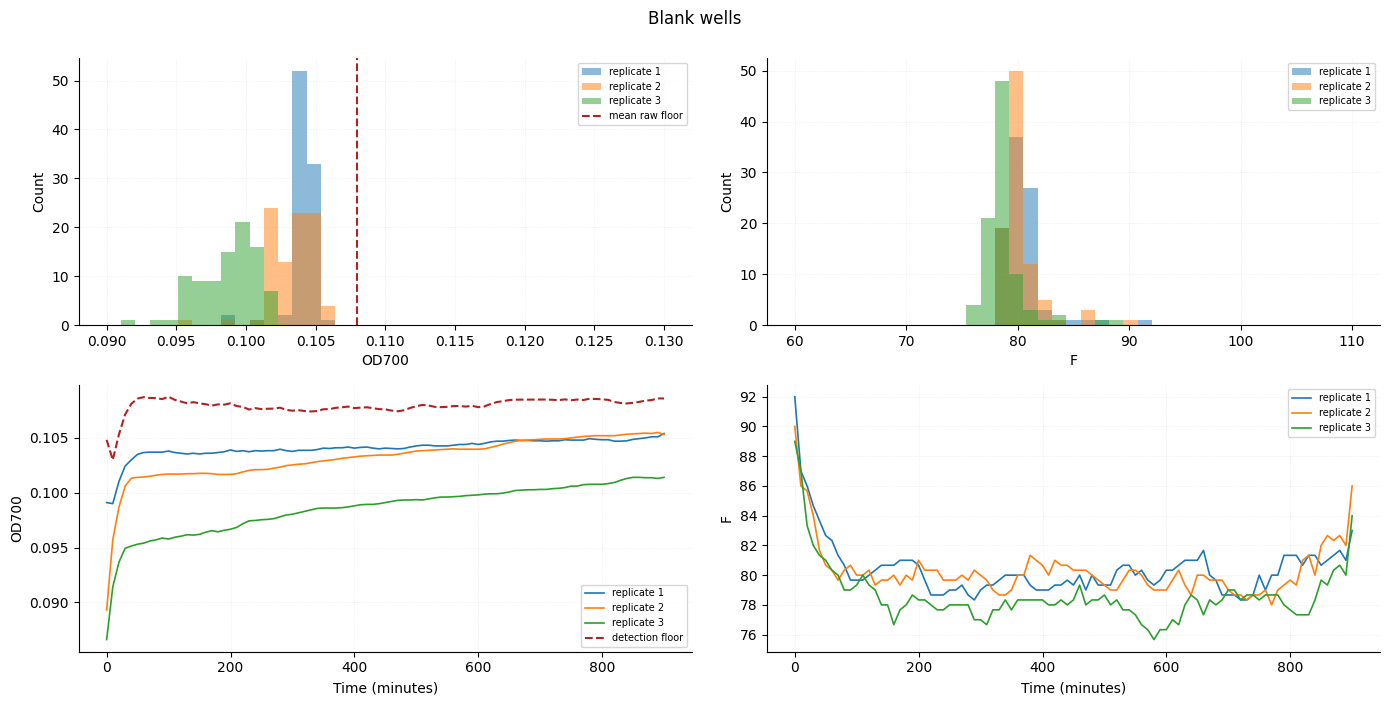

In [93]:
# Pooled blank; spread across replicates is the detection threshold
blank_od_wells = od_raw[list(CONTROL_ROWS), CONTROL_COLUMNS["blank"], :]
blank_fl_wells = fl_raw[list(CONTROL_ROWS), CONTROL_COLUMNS["blank"], :]

POOLED_BLANK, DETECTION_THRESHOLD = pooled_blank_and_threshold(blank_od_wells, "titration")
# Smoothed series, as the threshold uses
blank_od_wells = smooth(blank_od_wells)
blank_fl_wells = smooth(blank_fl_wells)
print(f"blank OD: pooled {POOLED_BLANK.min():.4f}-{POOLED_BLANK.max():.4f} "
      f"(rises {POOLED_BLANK[-1] - POOLED_BLANK[0]:+.4f} over the run)")
print(f"detection threshold on corrected OD: {DETECTION_THRESHOLD.min():.4f}-"
      f"{DETECTION_THRESHOLD.max():.4f}, median {np.median(DETECTION_THRESHOLD):.4f}")

figure, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, values, label, bins in (
        (axes[0, 0], blank_od_wells, "OD700", np.linspace(0.09, 0.13, 40)),
        (axes[0, 1], blank_fl_wells, "F", np.linspace(60, 110, 40))):
    for replicate in range(3):
        ax.hist(values[replicate], bins=bins, alpha=0.5, label=f"replicate {replicate + 1}")
    ax.set_xlabel(label)
    ax.set_ylabel("Count")
    ax.legend(fontsize=7)
# Raw-scale floor rises with the blank
axes[0, 0].axvline((POOLED_BLANK + DETECTION_THRESHOLD).mean(), color="firebrick", ls="--",
                   lw=1.5, label="mean raw floor")
axes[0, 0].legend(fontsize=7)
for ax, values, label in ((axes[1, 0], blank_od_wells, "OD700"),
                          (axes[1, 1], blank_fl_wells, "F")):
    for replicate in range(3):
        ax.plot(t_minutes, values[replicate], lw=1.2, label=f"replicate {replicate + 1}")
    if label == "OD700":
        ax.plot(t_minutes, POOLED_BLANK + DETECTION_THRESHOLD, color="firebrick", ls="--",
                lw=1.5, label="detection floor")
    ax.set_xlabel("Time (minutes)")
    ax.set_ylabel(label)
    ax.legend(fontsize=7)
for ax in axes.ravel():
    ax.grid(True, ls=":", alpha=0.3, linewidth=0.5)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
figure.suptitle("Blank wells", y=1.0)
figure.tight_layout()
if GENERATE_PDF:
    figure.savefig(OUT_DIR / "titration_blanks.pdf", dpi=PDF_DPI, bbox_inches="tight")
plt.show()

## Control Replicates

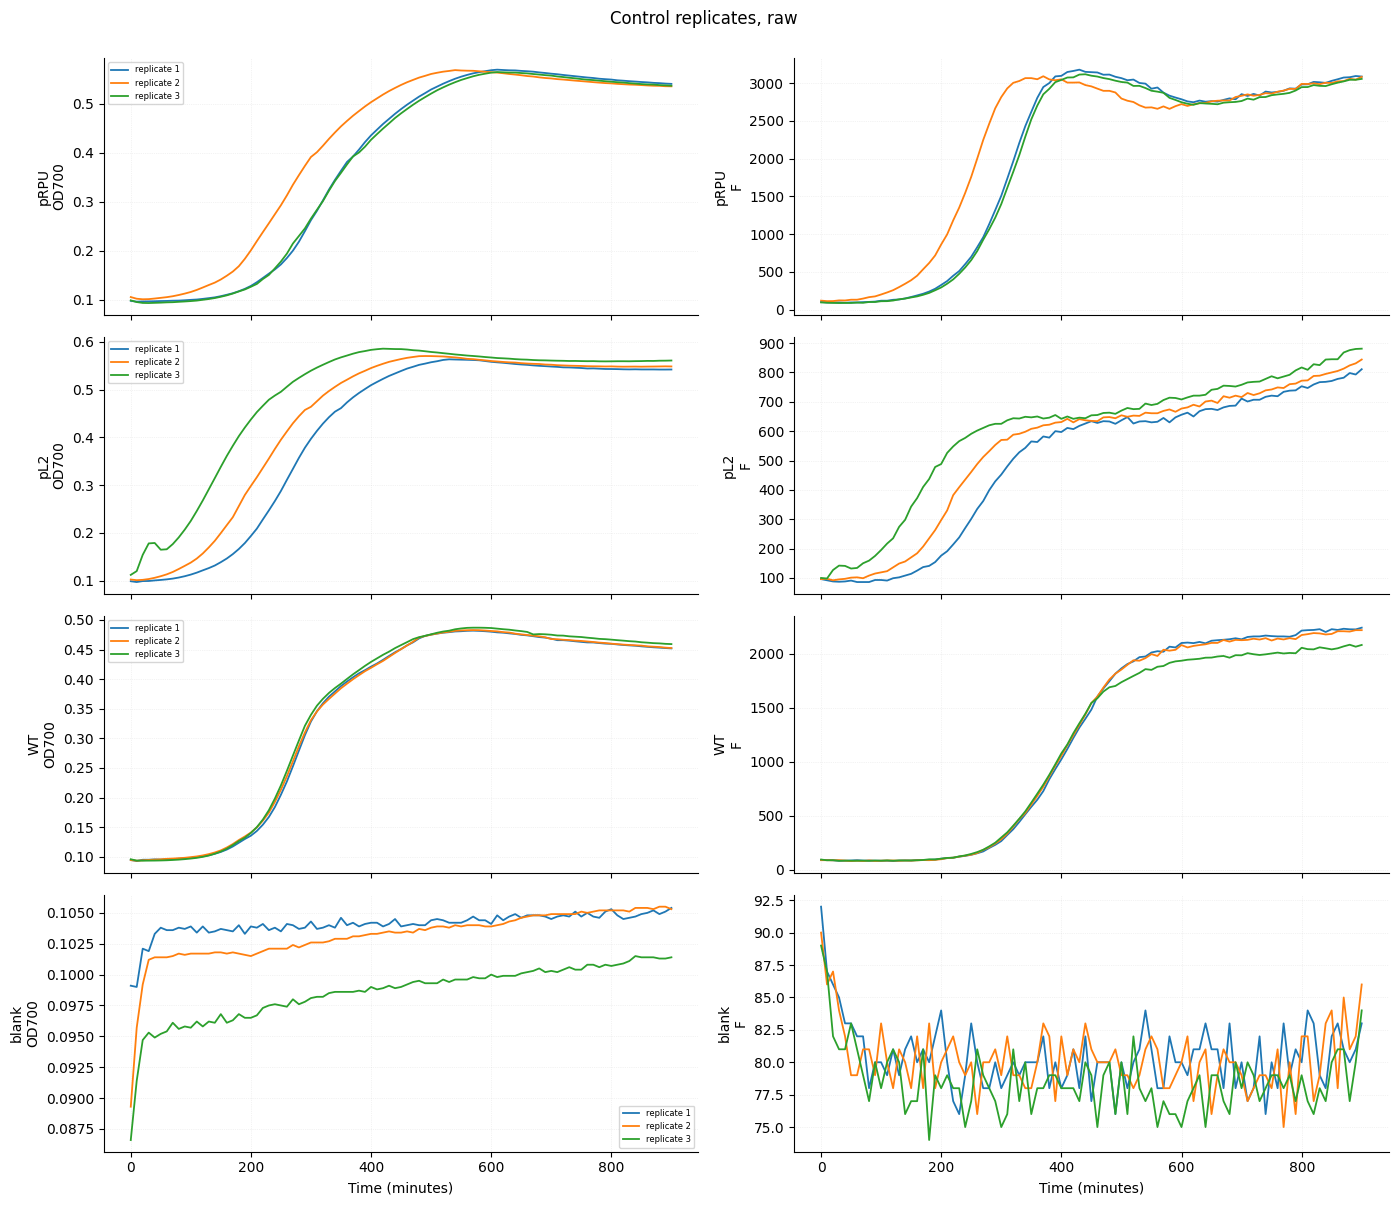

control  OD end CV %  F end CV %
   pRPU         0.40        0.45
    pL2         1.42        3.38
     WT         0.73        3.24
  blank         1.79        1.48


In [94]:
# All three replicates of every control, before averaging
figure, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)
for row, (name, column) in enumerate(CONTROL_COLUMNS.items()):
    for replicate, plate_row in enumerate(CONTROL_ROWS):
        axes[row, 0].plot(t_minutes, od_raw[plate_row, column], lw=1.3,
                          label=f"replicate {replicate + 1}")
        axes[row, 1].plot(t_minutes, fl_raw[plate_row, column], lw=1.3,
                          label=f"replicate {replicate + 1}")
    axes[row, 0].set_ylabel(f"{name}\nOD700")
    axes[row, 1].set_ylabel(f"{name}\nF")
    for ax in axes[row]:
        ax.grid(True, ls=":", alpha=0.3, linewidth=0.5)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
    axes[row, 0].legend(fontsize=6)
for ax in axes[-1]:
    ax.set_xlabel("Time (minutes)")
figure.suptitle("Control replicates, raw", y=1.0)
figure.tight_layout()
if GENERATE_PDF:
    figure.savefig(OUT_DIR / "titration_controls.pdf", dpi=PDF_DPI, bbox_inches="tight")
plt.show()

spread = pd.DataFrame(
    [{"control": name,
      "OD end CV %": round(100 * od_raw[list(CONTROL_ROWS), column, -1].std()
                           / od_raw[list(CONTROL_ROWS), column, -1].mean(), 2),
      "F end CV %": round(100 * fl_raw[list(CONTROL_ROWS), column, -1].std()
                          / fl_raw[list(CONTROL_ROWS), column, -1].mean(), 2)}
     for name, column in CONTROL_COLUMNS.items()])
print(spread.to_string(index=False))

## Background Subtraction

In [95]:
# Pooled blank for subtraction; no well excluded on this plate
blank_fl = pooled_blank_fl(
    fl_raw[list(CONTROL_ROWS), CONTROL_COLUMNS["blank"], :], "titration")

# [aTc, IPTG, time] for the titration grid.
# Smoothed, pooled-blank-corrected, and the floor tested on that same series.
grid_biomass, grid_above_floor = biomass_and_floor(
    od_raw[:GRID_ROWS, :GRID_COLS, :], POOLED_BLANK, DETECTION_THRESHOLD)
grid_fl = smooth(fl_raw[:GRID_ROWS, :GRID_COLS, :]) - blank_fl

# Controls keep their three replicates
controls_biomass, controls_fl, controls_above_floor = {}, {}, {}
for name, column in CONTROL_COLUMNS.items():
    if name == "blank":
        continue
    controls_biomass[name], controls_above_floor[name] = biomass_and_floor(
        od_raw[list(CONTROL_ROWS), column, :], POOLED_BLANK, DETECTION_THRESHOLD)
    controls_fl[name] = smooth(fl_raw[list(CONTROL_ROWS), column, :]) - blank_fl

print(f"grid above floor: {grid_above_floor.sum()} of {grid_above_floor.size} points")
print(f"  earliest above-floor timepoint {t_minutes[grid_above_floor.any(axis=(0, 1))][0]:.0f} min")

grid above floor: 4739 of 5824 points
  earliest above-floor timepoint 0 min


## Growth Rate and Sampling Point

In [96]:
# Growth rate: Savitzky-Golay


def savgol_growth_rate(od_series, t_arr):
    """Savitzky-Golay deriv=1 on ln(OD), per contiguous valid segment."""
    growth_rate = np.full_like(od_series, np.nan, dtype=float)
    dt = float(t_arr[1] - t_arr[0])
    for well in range(od_series.shape[0]):
        # Floor-off series dips to 0
        with np.errstate(invalid="ignore", divide="ignore"):
            ln_od = np.log(od_series[well])
        valid = np.isfinite(ln_od)
        # Longest contiguous finite run
        runs = np.flatnonzero(np.diff(np.r_[0, valid.astype(np.int8), 0])).reshape(-1, 2)
        if len(runs) == 0:
            continue
        first, stop = max(runs, key=lambda run: run[1] - run[0])
        if stop - first < SG_WINDOW:
            continue
        last = stop - 1
        deriv = savgol_filter(ln_od[first:last + 1], window_length=SG_WINDOW,
                              polyorder=SG_POLYORDER, deriv=1, delta=dt, mode="interp")
        growth_rate[well, first + SG_EDGE_EXCLUDE:last + 1 - SG_EDGE_EXCLUDE] = (
            deriv[SG_EDGE_EXCLUDE:len(deriv) - SG_EDGE_EXCLUDE])
    return growth_rate


# Helpers as in analyse_pr_biomass.ipynb


def exp_growth_window_indices(growth_rate_series):
    """(first, last) index of the exponential-growth window; None where nothing is finite."""
    if not np.isfinite(growth_rate_series).any():
        return None
    return transform.exp_growth_window(
        growth_rate_series, threshold=EXP_GROWTH_PHASE_THRESHOLD)


def window_middle(first_index, last_index):
    """Middle of a window, rounding up."""
    return (first_index + last_index + 1) // 2


def sample_index(growth_rate_series):
    """Index the pipeline samples: the middle of the exponential-growth window."""
    window = exp_growth_window_indices(growth_rate_series)
    return None if window is None else window_middle(*window)


def masked(values, mask):
    """The series with below-floor points removed."""
    return np.where(mask, values, np.nan)


# Fit grid_biomass, smoothed over every point including below-floor ones
grid_biomass_masked = masked(grid_biomass, grid_above_floor)
# Below the detection floor: drawn, never fitted
grid_biomass_excluded = masked(grid_biomass, ~grid_above_floor)

# grid flattened to [64, time] for the fit, then reshaped back
flat_growth_rate = savgol_growth_rate(
    grid_biomass_masked.reshape(-1, len(t_minutes)), t_minutes)
grid_growth_rate = flat_growth_rate.reshape(GRID_ROWS, GRID_COLS, -1)
grid_sample = np.array([[sample_index(grid_growth_rate[a, i])
                         for i in range(GRID_COLS)] for a in range(GRID_ROWS)])

controls_growth_rate, controls_sample = {}, {}
for name in controls_biomass:
    series = masked(controls_biomass[name], controls_above_floor[name])
    controls_growth_rate[name] = savgol_growth_rate(series, t_minutes)
    controls_sample[name] = [sample_index(controls_growth_rate[name][r]) for r in range(3)]

# the same fit with the floor off, for the faint comparison trace
grid_growth_rate_full = savgol_growth_rate(
    grid_biomass.reshape(-1, len(t_minutes)), t_minutes).reshape(GRID_ROWS, GRID_COLS, -1)
sampled_od = np.array([[grid_biomass_masked[a, i, grid_sample[a, i]]
                        for i in range(GRID_COLS)] for a in range(GRID_ROWS)])

# Window-derived quantities, as analyse_pr_biomass.ipynb reports
grid_window_points = np.full((GRID_ROWS, GRID_COLS), np.nan)
grid_mean_growth_rate = np.full((GRID_ROWS, GRID_COLS), np.nan)
grid_peak = np.full((GRID_ROWS, GRID_COLS), -1)
for a in range(GRID_ROWS):
    for i in range(GRID_COLS):
        series = grid_growth_rate[a, i]
        window = exp_growth_window_indices(series)
        if window is None:
            continue
        grid_window_points[a, i] = window[1] - window[0] + 1
        grid_mean_growth_rate[a, i] = np.nanmean(series[window[0]:window[1] + 1])
        grid_peak[a, i] = int(np.nanargmax(series))

print(f"sampled OD across the grid: {np.nanmin(sampled_od):.4f}-{np.nanmax(sampled_od):.4f}")
print(f"sampled time: {t_minutes[grid_sample].min():.0f}-{t_minutes[grid_sample].max():.0f} min")
print(f"95% window: median {np.nanmedian(grid_window_points):.0f} points, "
      f"{int(np.nansum(grid_window_points <= 2))} of {grid_window_points.size} at <= 2")
print(f"sampled point on the first readable timepoint: "
      f"{int(sum(grid_sample[a, i] == np.flatnonzero(np.isfinite(grid_growth_rate[a, i]))[0] for a in range(GRID_ROWS) for i in range(GRID_COLS)))} wells")
for name in controls_growth_rate:
    widths = [exp_growth_window_indices(controls_growth_rate[name][r]) for r in range(3)]
    widths = [np.nan if w is None else w[1] - w[0] + 1 for w in widths]
    rates = [controls_growth_rate[name][r][controls_sample[name][r]] for r in range(3)]
    print(f"  {name:5} window {widths}, growth rate at sampled "
          f"{np.round(rates, 5)}")

sampled OD across the grid: 0.0131-0.0986
sampled time: 180-330 min
95% window: median 2 points, 44 of 64 at <= 2
sampled point on the first readable timepoint: 28 wells
  pRPU  window [1, 3, 4], growth rate at sampled [0.02171 0.0185  0.02218]
  pL2   window [2, 1, 1], growth rate at sampled [0.01886 0.02164 0.01655]
  WT    window [4, 3, 5], growth rate at sampled [0.02181 0.02079 0.02233]


In [97]:
# One page per aTc level: ln(OD) and growth rate for its eight IPTG levels.
if not GENERATE_PDF:
    print("GENERATE_PDF is False: skipping the growth-rate PDF")
else:
    path = OUT_DIR / "titration_growth.pdf"
    started = time.perf_counter()
    colours = plt.cm.Reds(np.linspace(0.3, 1.0, GRID_COLS))
    with PdfPages(path) as pdf:
        for a in range(GRID_ROWS):
            figure, (ax_lod, ax_gr) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
            for i in range(GRID_COLS):
                # Below-floor points drawn, never fitted
                with np.errstate(invalid="ignore"):
                    ax_lod.scatter(t_minutes, np.log(grid_biomass_masked[a, i]), marker="x",
                                   color=colours[i], s=12, alpha=0.6, zorder=2,
                                   label=f"IPTG {IPTG_UM[i]:g} uM")
                    ax_lod.scatter(t_minutes, np.log(grid_biomass_excluded[a, i]), marker="o",
                                   color=colours[i], s=12, alpha=0.25, zorder=1)
                ax_gr.plot(t_minutes, grid_growth_rate[a, i], color=colours[i], lw=1.4)
                # same method over the full series, below-floor points included
                with np.errstate(invalid="ignore"):
                    ax_gr.plot(t_minutes, grid_growth_rate_full[a, i], color=colours[i],
                               lw=1.4, alpha=0.25, zorder=1)
                ax_gr.axvline(t_minutes[grid_sample[a, i]], color=colours[i], ls="-", lw=1.2,
                              alpha=0.8, zorder=0.5)
            ax_lod.set_ylabel("ln(OD)")
            ax_gr.set_ylabel("d ln(OD) / dt")
            ax_gr.set_xlabel("Time (minutes)")
            ax_lod.legend(fontsize=6, ncol=2)
            for ax in (ax_lod, ax_gr):
                ax.grid(True, ls=":", alpha=0.3, linewidth=0.5)
                for spine in ("top", "right"):
                    ax.spines[spine].set_visible(False)
            figure.suptitle(f"aTc {ATC_NG_ML[a]:g} ng/ml", y=0.995)
            figure.tight_layout()
            pdf.savefig(figure, dpi=PDF_DPI)
            plt.close(figure)
    print(f"{path}: {GRID_ROWS} pages, {time.perf_counter() - started:.0f}s")

/tmp/ipykernel_421961/2161493462.py:18: RuntimeWarning: divide by zero encountered in log
  ax_lod.scatter(t_minutes, np.log(grid_biomass_excluded[a, i]), marker="o",


out/titration_growth.pdf: 8 pages, 2s


## Effect of IPTG on Growth

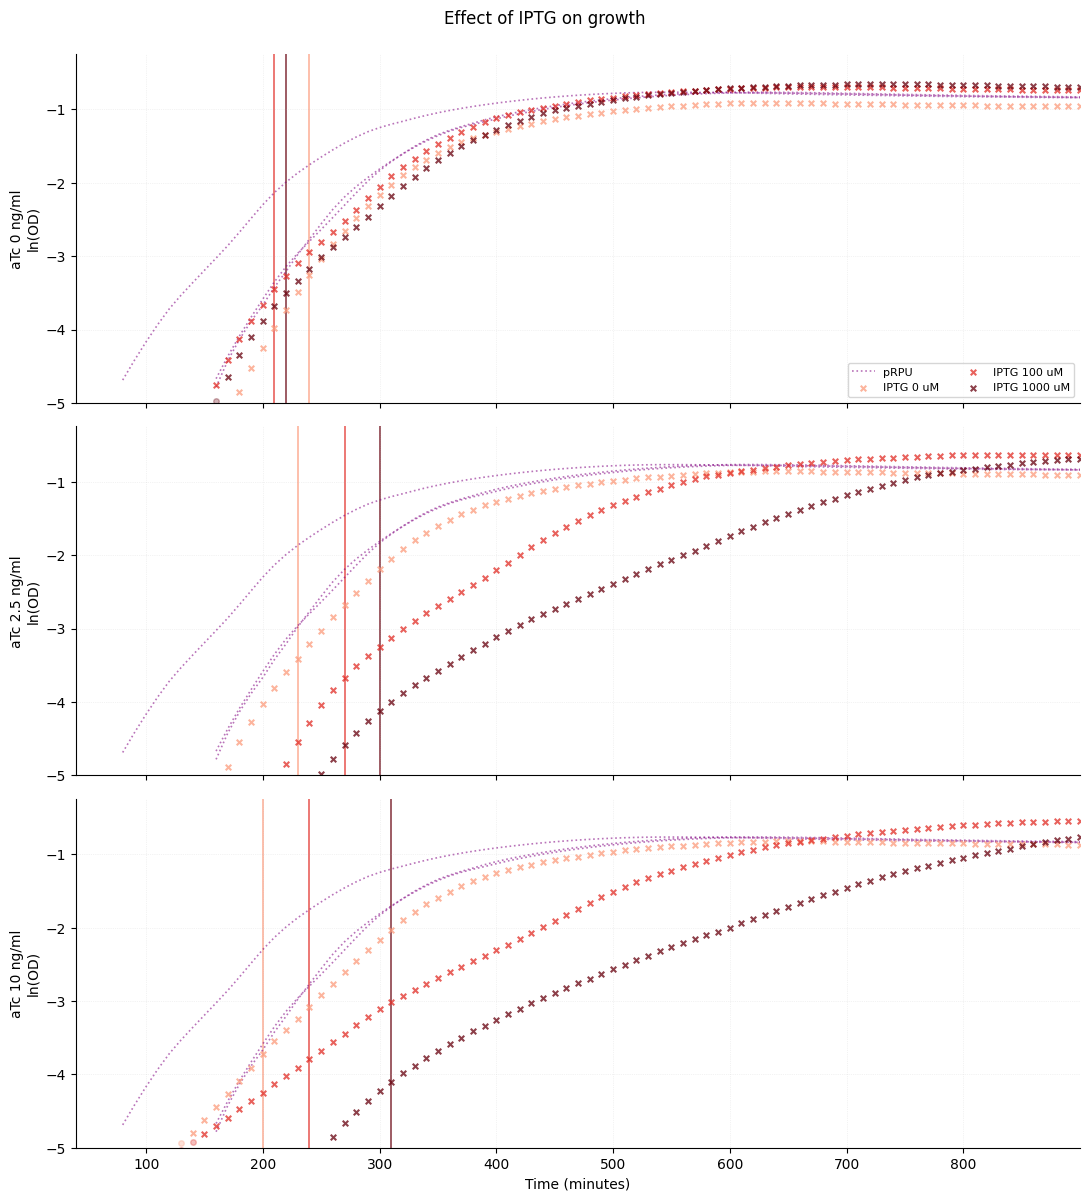

growth rate at the sampled point (1/min), and the time it falls at

rate
          IPTG 0  IPTG 100  IPTG 1000
aTc 0    0.02234   0.01964    0.01772
aTc 2.5  0.01929   0.01667    0.01357
aTc 10   0.01740   0.01160    0.01191

time (min)
            IPTG 0   IPTG 100  IPTG 1000
aTc 0    239.90000  209.88333      219.9
aTc 2.5  229.90000  269.90000      299.9
aTc 10   199.88333  239.90000      309.9

104 below-floor grid points have a blank-corrected OD <= 0 and cannot be drawn on a log axis at all


In [98]:
# Measured ln(OD), one row per aTc level
# pRPU as one dotted line per replicate
with np.errstate(invalid="ignore"):
    prpu_ln_od = np.log(masked(controls_biomass["pRPU"], controls_above_floor["pRPU"]))

# Upper limit from the data; floor hardcoded, clipping 14 below-floor points
shown = slice(GROWTH_SKIP_POINTS, None)
with np.errstate(invalid="ignore"):
    drawn_ln_od = np.concatenate(
        [np.log(series[a, i][shown]) for a in GROWTH_ATC_ROWS for i in GROWTH_IPTG_COLUMNS
         for series in (grid_biomass_masked, grid_biomass_excluded)]
        + [prpu_ln_od[:, shown].ravel()])
drawn_ln_od = drawn_ln_od[np.isfinite(drawn_ln_od)]
LN_OD_LIMITS = (LN_OD_LOWER_LIMIT, drawn_ln_od.max() + 0.3)

figure, axes = plt.subplots(len(GROWTH_ATC_ROWS), 1, figsize=FIGSIZE_IPTG_GROWTH,
                            sharex=True, sharey=True)
for ax, a, atc in zip(axes, GROWTH_ATC_ROWS, GROWTH_ATC_NG_ML):
    first_row = a == GROWTH_ATC_ROWS[0]
    for replicate in range(3):
        ax.plot(t_minutes, prpu_ln_od[replicate], color=GROWTH_PRPU_COLOUR, ls=":", lw=1.2,
                alpha=0.55, zorder=1.6,
                label="pRPU" if first_row and replicate == 0 else None)

    for colour, i, iptg in zip(GROWTH_COLOURS, GROWTH_IPTG_COLUMNS, GROWTH_IPTG_UM):
        with np.errstate(invalid="ignore"):
            ax.scatter(t_minutes, np.log(grid_biomass_masked[a, i]), marker="x",
                       color=colour, s=16, alpha=0.75, zorder=2,
                       label=f"IPTG {iptg:g} uM" if first_row else None)
            ax.scatter(t_minutes, np.log(grid_biomass_excluded[a, i]), marker="o",
                       color=colour, s=16, alpha=0.3, zorder=1)
        ax.axvline(t_minutes[grid_sample[a, i]], color=colour, ls="-", lw=1.2,
                   alpha=0.75, zorder=0.5)

    ax.set_ylabel(f"aTc {atc:g} ng/ml\nln(OD)")
    ax.set_xlim(t_minutes[GROWTH_SKIP_POINTS], t_minutes[-1])
    ax.set_ylim(*LN_OD_LIMITS)
    ax.grid(True, ls=":", alpha=0.3, linewidth=0.5)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
axes[0].legend(fontsize=8, loc="lower right", ncol=2)
axes[-1].set_xlabel("Time (minutes)")
figure.suptitle(GROWTH_TITLE, y=0.997)
figure.tight_layout()
plt.show()

# the numbers behind the figure, read where the vline is drawn
print("growth rate at the sampled point (1/min), and the time it falls at\n")
for label, values in (("rate", lambda a, i: grid_growth_rate[a, i, grid_sample[a, i]]),
                      ("time (min)", lambda a, i: t_minutes[grid_sample[a, i]])):
    print(f"{label}")
    print(pd.DataFrame(
        {f"IPTG {iptg:g}": {f"aTc {atc:g}": values(a, i)
                            for a, atc in zip(GROWTH_ATC_ROWS, GROWTH_ATC_NG_ML)}
         for i, iptg in zip(GROWTH_IPTG_COLUMNS, GROWTH_IPTG_UM)}).round(5).to_string())
    print()
unplottable = sum(int((~grid_above_floor[a, i] & (grid_biomass[a, i] <= 0)).sum())
                  for a in GROWTH_ATC_ROWS for i in GROWTH_IPTG_COLUMNS)
print(f"{unplottable} below-floor grid points have a blank-corrected OD <= 0 and cannot be "
      f"drawn on a log axis at all")

## Autofluorescence Calibration

In [99]:
# Autofluorescence against OD, fitted to the pL2 backbone
# AUTOFLUORESCENCE_OD_RANGE stands in for PL2_FIT_CUTOFF
# (Fedorec et al. 2020, doi:10.1021/acssynbio.0c00296)

AUTOFLUORESCENCE_OD_RANGE = (0.01, 0.12)

# Three pL2 replicates pooled into one curve
pl2_od = controls_biomass["pL2"]
pl2_fl = controls_fl["pL2"]
# Truncation here; floor and finite rule in the helper
pl2_in_window = ((pl2_od >= AUTOFLUORESCENCE_OD_RANGE[0])
                 & (pl2_od <= AUTOFLUORESCENCE_OD_RANGE[1]))
AUTOFLUORESCENCE_COEFFS, AUTOFLUORESCENCE_OD_SPAN, fitted = transform.fit_autofluorescence(
    pl2_od[pl2_in_window], pl2_fl[pl2_in_window],
    controls_above_floor["pL2"][pl2_in_window], order=AUTOFLUORESCENCE_ORDER)

# Points the fit used, in [replicate, time]
pl2_fitted = np.zeros_like(pl2_in_window)
pl2_fitted[pl2_in_window] = fitted


def predict_autofluorescence(od):
    """pL2 autofluorescence at a given OD, from the fitted curve."""
    return transform.autofluorescence_at(AUTOFLUORESCENCE_COEFFS, od)


residual = pl2_fl[pl2_fitted] - predict_autofluorescence(pl2_od[pl2_fitted])
AUTOFLUORESCENCE_R2 = float(
    1 - (residual ** 2).sum() / ((pl2_fl[pl2_fitted] - pl2_fl[pl2_fitted].mean()) ** 2).sum())
print(f"pL2 autofluorescence: order {AUTOFLUORESCENCE_ORDER} on {int(pl2_fitted.sum())} points "
      f"over OD {AUTOFLUORESCENCE_OD_SPAN[0]:.4f}-{AUTOFLUORESCENCE_OD_SPAN[1]:.4f}")
print(f"  R2 {AUTOFLUORESCENCE_R2:.4f}, RMSE {np.sqrt((residual ** 2).mean()):.2f}")
print("\nNote: the correction is not a constant, so it does NOT cancel out of dG/dt --")
print("dG/dt = dF/dt - (dA/dOD) * dOD/dt, and a polynomial's slope dA/dOD varies with OD -- so")
print("it moves every synthesis rate and RPU, not just the G panels.")

pL2 autofluorescence: order 3 on 33 points over OD 0.0123-0.1155
  R2 0.9571, RMSE 5.98

Note: the correction is not a constant, so it does NOT cancel out of dG/dt --
dG/dt = dF/dt - (dA/dOD) * dOD/dt, and a polynomial's slope dA/dOD varies with OD -- so
it moves every synthesis rate and RPU, not just the G panels.


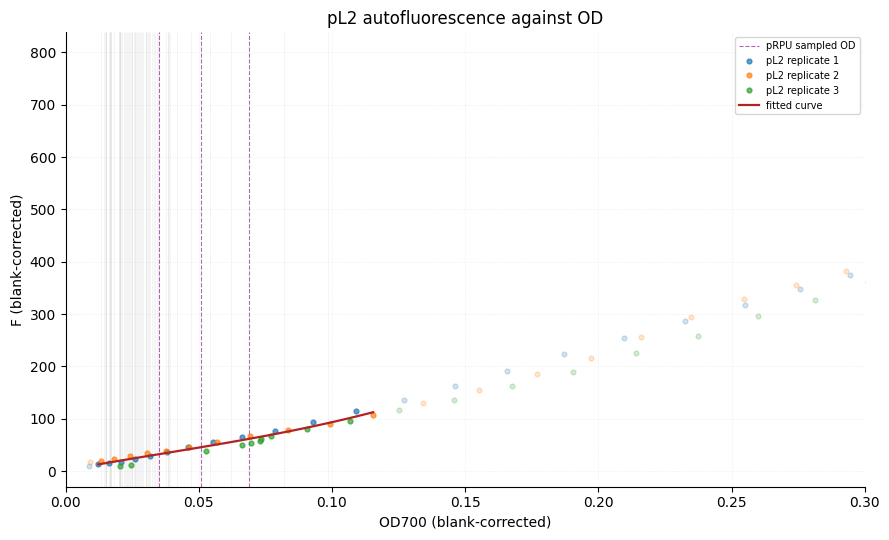

grid sampling OD: 0.0131-0.0986; 0 of 64 wells sample outside the fitted range


In [100]:
# Calibration curve, with every sampled OD underneath
# Linear axes
figure, ax = plt.subplots(figsize=(9, 5.5))

# Every grid well's sampled OD
ax.vlines(sampled_od[np.isfinite(sampled_od)].ravel(), 0, 1,
          transform=ax.get_xaxis_transform(), color="gray", lw=0.4, alpha=0.15, zorder=1)
for replicate in range(3):
    index = controls_sample["pRPU"][replicate]
    if index is not None:
        ax.axvline(controls_biomass["pRPU"][replicate][index], color="purple", ls="--", lw=0.8,
                   alpha=0.6, zorder=2, label="pRPU sampled OD" if replicate == 0 else None)

for replicate in range(3):
    od_well = controls_biomass["pL2"][replicate]
    fl_well = controls_fl["pL2"][replicate]
    drawn = (np.isfinite(od_well) & np.isfinite(fl_well) & (od_well > 0)
             & controls_above_floor["pL2"][replicate])
    # Membership from the fit itself
    in_fit = pl2_fitted[replicate]
    # Below-floor points excluded from the fit
    ax.plot(od_well[drawn & ~in_fit], fl_well[drawn & ~in_fit], "o", ms=3.5, alpha=0.2,
            color=f"C{replicate}", zorder=3)
    ax.plot(od_well[in_fit], fl_well[in_fit], "o", ms=3.5, alpha=0.7, color=f"C{replicate}",
            zorder=3, label=f"pL2 replicate {replicate + 1}")

# Curve drawn over the fitted span only
od_line = np.linspace(*AUTOFLUORESCENCE_OD_SPAN, 100)
ax.plot(od_line, predict_autofluorescence(od_line), color="firebrick", lw=1.6, zorder=4,
        label="fitted curve")
# Past OD 0.3 the curve turns over; nothing is read there
ax.set_xlim(0, 0.3)
ax.set_xlabel("OD700 (blank-corrected)")
ax.set_ylabel("F (blank-corrected)")
ax.set_title("pL2 autofluorescence against OD")
ax.legend(fontsize=7)
ax.grid(True, ls=":", alpha=0.3, linewidth=0.5)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
figure.tight_layout()
if GENERATE_PDF:
    figure.savefig(OUT_DIR / "titration_calibration.pdf", dpi=PDF_DPI, bbox_inches="tight")
plt.show()

sampled = sampled_od[np.isfinite(sampled_od)]
outside = int(((sampled < AUTOFLUORESCENCE_OD_SPAN[0])
               | (sampled > AUTOFLUORESCENCE_OD_SPAN[1])).sum())
print(f"grid sampling OD: {sampled.min():.4f}-{sampled.max():.4f}; "
      f"{outside} of {sampled.size} wells sample outside the fitted range")

## Synthesis Rate and RPU

In [101]:
# G is the circuit's own fluorescence, autofluorescence removed; phi is its rate of
# production per unit biomass; RPU divides that by the pRPU standard.


def synthesis_rate(od_series, fl_series, above, index):
    """(G, dG/dt, phi) at one sampled index; NaN where the series cannot support a derivative."""
    if index is None:
        return np.nan, np.nan, np.nan
    usable = above & np.isfinite(od_series) & np.isfinite(fl_series) & (od_series > 0)
    g_series = np.where(usable, fl_series - predict_autofluorescence(od_series), np.nan)
    # Savitzky-Golay on the real time grid; ends stay NaN
    derivative = dg_dt(g_series, t_minutes)
    if not np.isfinite(derivative[index]) or not od_series[index] > 0:
        return g_series[index], np.nan, np.nan
    return g_series[index], derivative[index], derivative[index] / od_series[index]


grid_phi = np.full((GRID_ROWS, GRID_COLS), np.nan)
grid_g = np.full((GRID_ROWS, GRID_COLS), np.nan)
grid_dg = np.full((GRID_ROWS, GRID_COLS), np.nan)
for row in range(GRID_ROWS):
    for column in range(GRID_COLS):
        grid_g[row, column], grid_dg[row, column], grid_phi[row, column] = synthesis_rate(
            grid_biomass[row, column], grid_fl[row, column], grid_above_floor[row, column],
            grid_sample[row, column])

controls_phi = {}
for name in controls_biomass:
    controls_phi[name] = np.array([
        synthesis_rate(controls_biomass[name][r], controls_fl[name][r],
                       controls_above_floor[name][r], controls_sample[name][r])[2]
        for r in range(3)])

# the standard: the three pRPU replicates averaged, their spread reported as QC
rpu_denominator = float(np.nanmean(controls_phi["pRPU"]))
print(f"pRPU phi per replicate: {np.round(controls_phi['pRPU'], 2)}")
print(f"  mean {rpu_denominator:.2f}, CV {100 * np.nanstd(controls_phi['pRPU']) / rpu_denominator:.1f}%")

grid_rpu = grid_phi / rpu_denominator
controls_rpu = {name: values / rpu_denominator for name, values in controls_phi.items()}
print(f"\ngrid RPU: {np.nanmin(grid_rpu):.3f}-{np.nanmax(grid_rpu):.3f}")
print(f"pL2 RPU {np.round(controls_rpu['pL2'], 3)}   WT RPU {np.round(controls_rpu['WT'], 3)}")

records = [{"aTc_ng_ml": ATC_NG_ML[row], "aTc_uM": round(ATC_UM[row], 5),
            "IPTG_uM": IPTG_UM[column],
            "window_points": grid_window_points[row, column],
            "t_sampled": round(float(t_minutes[grid_sample[row, column]]), 1),
            "biomass_at_sampled": round(float(sampled_od[row, column]), 5),
            "growth_rate_at_sampled": round(
                float(grid_growth_rate[row, column, grid_sample[row, column]]), 5),
            "mean_growth_rate_95pct": round(float(grid_mean_growth_rate[row, column]), 5),
            "max_growth_rate": round(
                float(grid_growth_rate[row, column, grid_peak[row, column]]), 5),
            "G_at_sampled": round(float(grid_g[row, column]), 3),
            "dG_dt_at_sampled": round(float(grid_dg[row, column]), 5),
            "synthesis_rate": round(float(grid_phi[row, column]), 3),
            "RPU": round(float(grid_rpu[row, column]), 4)}
           for row in range(GRID_ROWS) for column in range(GRID_COLS)]
titration = pd.DataFrame(records)
titration.to_csv(OUT_DIR / "analyse_pr_titration.csv", index=False)
titration.head()

pRPU phi per replicate: [151.81 124.54 134.43]
  mean 136.92, CV 8.2%

grid RPU: 1.496-89.551
pL2 RPU [ 0.045 -0.008 -0.049]   WT RPU [-0.083 -0.067 -0.057]


,aTc_ng_ml,aTc_uM,IPTG_uM,window_points,t_sampled,biomass_at_sampled,growth_rate_at_sampled,mean_growth_rate_95pct,max_growth_rate,G_at_sampled,dG_dt_at_sampled,synthesis_rate,RPU
0,0.0,0.0,0.0,2.0,239.9,0.03837,0.02234,0.02286,0.02339,579.161,11.96645,311.897,2.2779
1,0.0,0.0,2.5,1.0,219.9,0.03413,0.01922,0.01922,0.01922,465.385,8.67773,254.230,1.8567
2,0.0,0.0,10.0,1.0,189.9,0.02494,0.01733,0.01733,0.01733,259.369,5.10968,204.843,1.4960
3,0.0,0.0,25.0,1.0,219.9,0.03763,0.01964,0.01964,0.01964,568.777,11.27026,299.475,2.1872
4,0.0,0.0,50.0,2.0,189.9,0.02591,0.01847,0.01876,0.01906,706.548,14.79263,570.899,4.1694


## RPU Bars

In [ ]:
# Synthrate bar format, one page per aTc level, plus an 8x8 overview
WT_BAND = (min(0.0, float(np.nanmin(controls_rpu["WT"]))),
           max(0.0, float(np.nanmax(controls_rpu["WT"]))))
PL2_BAND = (min(0.0, float(np.nanmin(controls_rpu["pL2"]))),
            max(0.0, float(np.nanmax(controls_rpu["pL2"]))))

# Linear stretch sized to the pL2 band, rounded up to a decade
RPU_LINTHRESH = 10.0 ** np.ceil(np.log10(max(PL2_BAND[1], -PL2_BAND[0])))
RPU_LINSCALE = 0.2
RPU_LIMITS = (0, max(np.nanmax(grid_rpu), PL2_BAND[1]) * 1.6)


def draw_bars(ax, row, annotate=True):
    """RPU across the eight IPTG levels at one aTc level."""
    centres = np.arange(GRID_COLS)
    ax.axhspan(*WT_BAND, color="gray", alpha=0.15, zorder=0, linewidth=0)
    ax.axhspan(*PL2_BAND, color="gold", alpha=0.22, zorder=0, linewidth=0)
    ax.bar(centres, np.where(grid_rpu[row] > 0, grid_rpu[row], np.nan), width=0.62,
           color="tab:blue", edgecolor="black", linewidth=0.5, zorder=2)
    ax.axhline(0, color="gray", lw=0.8, zorder=0)
    # both controls through the same pipeline, each in its own band's colour
    for control, control_colour in (("WT", "dimgray"), ("pL2", "darkgoldenrod")):
        for replicate in range(3):
            ax.scatter(centres, np.full(GRID_COLS, controls_rpu[control][replicate]),
                       marker="_", color=control_colour, s=60, linewidths=1.0, zorder=3,
                       label=control if replicate == 0 and annotate else None)
    ax.set_yscale("symlog", linthresh=RPU_LINTHRESH, linscale=RPU_LINSCALE)
    ax.set_ylim(*RPU_LIMITS)
    ax.set_xticks(centres)
    ax.set_xticklabels([f"{value:g}" for value in IPTG_UM], fontsize=7)
    ax.grid(True, axis="y", ls=":", alpha=0.3, linewidth=0.5)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)


if not GENERATE_PDF:
    print("GENERATE_PDF is False: skipping the bar PDF")
else:
    path = OUT_DIR / "titration_bars.pdf"
    started = time.perf_counter()
    with PdfPages(path) as pdf:
        for row in range(GRID_ROWS):
            figure, ax = plt.subplots(figsize=(9, 5.5))
            draw_bars(ax, row)
            ax.set_xlabel("IPTG (uM)")
            ax.set_ylabel("Output (RPU)")
            ax.set_title(f"aTc {ATC_NG_ML[row]:g} ng/ml ({ATC_UM[row] * 1000:.1f} nM)")
            ax.legend(fontsize=7)
            figure.tight_layout()
            pdf.savefig(figure, dpi=PDF_DPI)
            plt.close(figure)
        # one overview page: the whole grid at a glance
        figure, axes = plt.subplots(GRID_ROWS, 1, figsize=(10, 22), sharex=True, sharey=True)
        for row in range(GRID_ROWS):
            draw_bars(axes[row], row, annotate=row == 0)
            axes[row].set_ylabel(f"aTc {ATC_NG_ML[row]:g}\nng/ml", fontsize=8)
        axes[-1].set_xlabel("IPTG (uM)")
        axes[0].legend(fontsize=7)
        figure.suptitle("Circuit 75 — RPU across the full aTc x IPTG grid", y=0.999)
        figure.tight_layout()
        pdf.savefig(figure, dpi=PDF_DPI)
        plt.close(figure)
    print(f"{path}: {GRID_ROWS + 1} pages, {time.perf_counter() - started:.0f}s")

out/titration_bars.pdf: 9 pages, 3s


## Dose Response

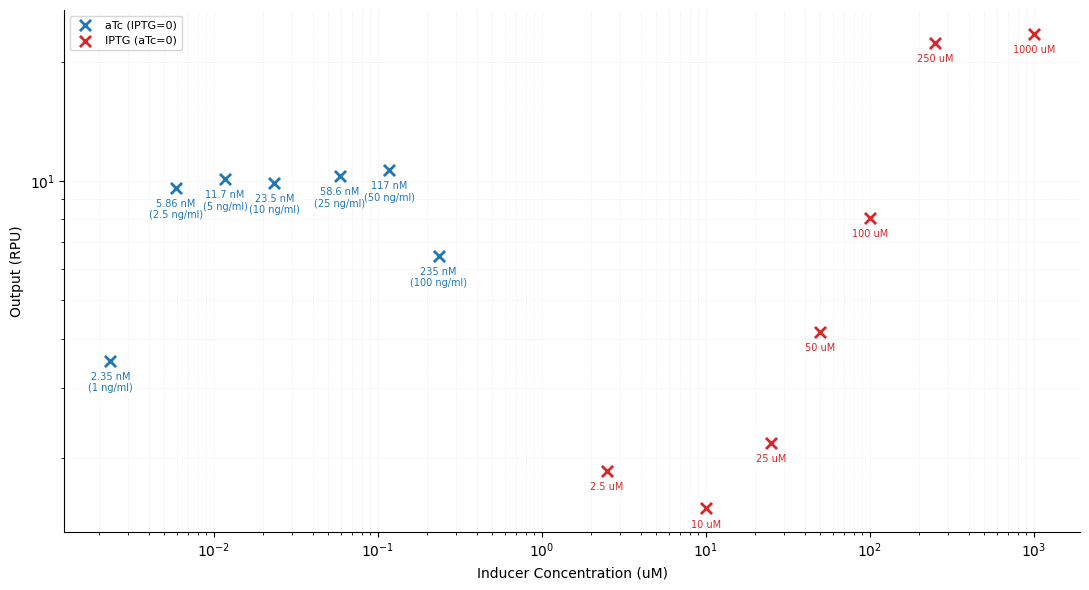

In [103]:
# Each input scanned with the other held at zero, every marker labelled
# Zero concentration absent on a log axis; it is in the bars and CSV

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(ATC_UM[1:], grid_rpu[1:, 0], color="tab:blue", marker="x", s=64, linewidth=2,
           label="aTc (IPTG=0)")
ax.scatter(IPTG_UM[1:], grid_rpu[0, 1:], color="tab:red", marker="x", s=64, linewidth=2,
           label="IPTG (aTc=0)")

for atc_uM, atc_ng_ml, y in zip(ATC_UM[1:], ATC_NG_ML[1:], grid_rpu[1:, 0]):
    ax.annotate(f"{atc_uM * 1000:.3g} nM\n({atc_ng_ml:g} ng/ml)", xy=(atc_uM, y),
                xytext=(0, -8), textcoords="offset points", fontsize=7, ha="center",
                va="top", color="tab:blue")
for iptg_uM, y in zip(IPTG_UM[1:], grid_rpu[0, 1:]):
    ax.annotate(f"{iptg_uM:g} uM", xy=(iptg_uM, y), xytext=(0, -8),
                textcoords="offset points", fontsize=7, ha="center", va="top",
                color="tab:red")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Inducer Concentration (uM)")
ax.set_ylabel("Output (RPU)")
ax.grid(True, which="both", ls=":", alpha=0.3, linewidth=0.5)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

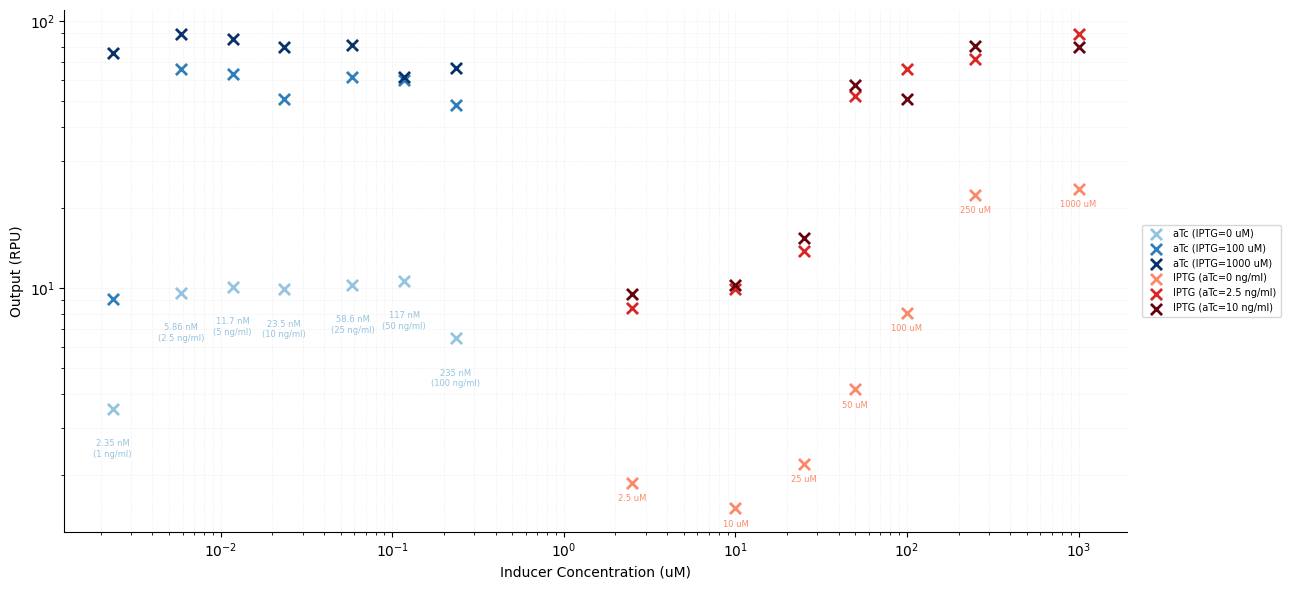

In [ ]:
# Dose response at the sampled timepoint, both inputs on one log-concentration axis

fig, ax = plt.subplots(figsize=(13, 6))
for series, (column, iptg_uM) in enumerate(zip(DOSE_IPTG_COLUMNS, DOSE_IPTG_UM)):
    values = grid_rpu[1:, column]
    ax.scatter(ATC_UM[1:], values, color=ATC_SERIES_COLOURS[series], marker="x", s=64,
               linewidth=2, label=f"aTc (IPTG={iptg_uM:g} uM)")
    # Label the bottom curve only
    if series == 0:
        for atc_uM, atc_ng_ml, y in zip(ATC_UM[1:], ATC_NG_ML[1:], values):
            ax.annotate(f"{atc_uM * 1000:.3g} nM\n({atc_ng_ml:g} ng/ml)", xy=(atc_uM, y),
                        xytext=(0, DOSE_ATC_LABEL_OFFSET), textcoords="offset points",
                        fontsize=6, ha="center", va="top",
                        color=ATC_SERIES_COLOURS[series])

for series, (row, atc_ng_ml) in enumerate(zip(DOSE_ATC_ROWS, DOSE_ATC_NG_ML)):
    values = grid_rpu[row, 1:]
    ax.scatter(IPTG_UM[1:], values, color=IPTG_SERIES_COLOURS[series], marker="x", s=64,
               linewidth=2, label=f"IPTG (aTc={atc_ng_ml:g} ng/ml)")
    if series == 0:
        for iptg_uM, y in zip(IPTG_UM[1:], values):
            ax.annotate(f"{iptg_uM:g} uM", xy=(iptg_uM, y),
                        xytext=(0, DOSE_IPTG_LABEL_OFFSET), textcoords="offset points",
                        fontsize=6, ha="center", va="top",
                        color=IPTG_SERIES_COLOURS[series])

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Inducer Concentration (uM)")
ax.set_ylabel("Output (RPU)")
ax.grid(True, which="both", ls=":", alpha=0.3, linewidth=0.5)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()

In [105]:
# Each input titrated with the other held at zero: RPU over time, then sampled RPU against concentration
if not GENERATE_PDF:
    print("GENERATE_PDF is False: skipping the dose-response PDF")
else:
    path = OUT_DIR / "titration_dose_response.pdf"
    started = time.perf_counter()
    with PdfPages(path) as pdf:
        for label, series, concentrations, colourmap, unit in (
                ("aTc (IPTG=0)", grid_rpu[:, 0], ATC_NG_ML, plt.cm.Blues, "ng/ml"),
                ("IPTG (aTc=0)", grid_rpu[0, :], IPTG_UM, plt.cm.Reds, "uM")):
            figure, ax = plt.subplots(figsize=(12, 6))
            colours = colourmap(np.linspace(0.3, 1.0, 8))
            ax.bar(np.arange(8), np.where(series > 0, series, np.nan), width=0.62,
                   color=colours, edgecolor="black", linewidth=0.5)
            ax.axhspan(*WT_BAND, color="gray", alpha=0.15, zorder=0, linewidth=0)
            ax.axhspan(*PL2_BAND, color="gold", alpha=0.22, zorder=0, linewidth=0)
            ax.set_yscale("symlog", linthresh=RPU_LINTHRESH, linscale=RPU_LINSCALE)
            ax.set_xticks(np.arange(8))
            ax.set_xticklabels([f"{value:g}" for value in concentrations])
            ax.set_xlabel(f"{label.split()[0]} ({unit})")
            ax.set_ylabel("Output (RPU)")
            ax.set_title(f"Sampled RPU — {label}")
            ax.grid(True, axis="y", ls=":", alpha=0.3, linewidth=0.5)
            for spine in ("top", "right"):
                ax.spines[spine].set_visible(False)
            figure.tight_layout()
            pdf.savefig(figure, dpi=PDF_DPI)
            plt.close(figure)

        # Both inputs on one log-concentration axis
        figure, ax = plt.subplots(figsize=(13, 6))
        for series, (column, iptg_uM) in enumerate(zip(DOSE_IPTG_COLUMNS, DOSE_IPTG_UM)):
            values = grid_rpu[1:, column]
            ax.scatter(ATC_UM[1:], values, color=ATC_SERIES_COLOURS[series], marker="x", s=64,
                       linewidth=2, label=f"aTc (IPTG={iptg_uM:g} uM)")
            # Label the bottom curve only
            if series == 0:
                for atc_uM, atc_ng_ml, y in zip(ATC_UM[1:], ATC_NG_ML[1:], values):
                    ax.annotate(f"{atc_uM * 1000:.3g} nM\n({atc_ng_ml:g} ng/ml)", xy=(atc_uM, y),
                                xytext=(0, -8), textcoords="offset points", fontsize=6, ha="center",
                                va="top", color=ATC_SERIES_COLOURS[series])

        for series, (row, atc_ng_ml) in enumerate(zip(DOSE_ATC_ROWS, DOSE_ATC_NG_ML)):
            values = grid_rpu[row, 1:]
            ax.scatter(IPTG_UM[1:], values, color=IPTG_SERIES_COLOURS[series], marker="x", s=64,
                       linewidth=2, label=f"IPTG (aTc={atc_ng_ml:g} ng/ml)")
            if series == 0:
                for iptg_uM, y in zip(IPTG_UM[1:], values):
                    ax.annotate(f"{iptg_uM:g} uM", xy=(iptg_uM, y), xytext=(0, -8),
                                textcoords="offset points", fontsize=6, ha="center", va="top",
                                color=IPTG_SERIES_COLOURS[series])

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("Inducer (uM)")
        ax.set_ylabel("Output (RPU)")
        ax.set_title("Dose response at the sampled timepoint")
        ax.grid(True, which="both", ls=":", alpha=0.3, linewidth=0.5)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
        ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
        figure.tight_layout()
        pdf.savefig(figure, dpi=PDF_DPI)
        plt.close(figure)
    print(f"{path}: 3 pages, {time.perf_counter() - started:.0f}s")

out/titration_dose_response.pdf: 3 pages, 2s
